# Frequentist Inference Case Study - Part B

## Learning objectives

Welcome to Part B of the Frequentist inference case study! The purpose of this case study is to help you apply the concepts associated with Frequentist inference in Python. In particular, you'll practice writing Python code to apply the following statistical concepts: 
* the _z_-statistic
* the _t_-statistic
* the difference and relationship between the two
* the Central Limit Theorem, including its assumptions and consequences
* how to estimate the population mean and standard deviation from a sample
* the concept of a sampling distribution of a test statistic, particularly for the mean
* how to combine these concepts to calculate a confidence interval

In the previous notebook, we used only data from a known normal distribution. **You'll now tackle real data, rather than simulated data, and answer some relevant real-world business problems using the data.**

## Hospital medical charges

Imagine that a hospital has hired you as their data scientist. An administrator is working on the hospital's business operations plan and needs you to help them answer some business questions. 

In this assignment notebook, you're going to use frequentist statistical inference on a data sample to answer the questions:
* has the hospital's revenue stream fallen below a key threshold?
* are patients with insurance really charged different amounts than those without?

Answering that last question with a frequentist approach makes some assumptions, and requires some knowledge, about the two groups.

We are going to use some data on medical charges obtained from [Kaggle](https://www.kaggle.com/easonlai/sample-insurance-claim-prediction-dataset). 

For the purposes of this exercise, assume the observations are the result of random sampling from our single hospital. Recall that in the previous assignment, we introduced the Central Limit Theorem (CLT), and its consequence that the distributions of sample statistics approach a normal distribution as $n$ increases. The amazing thing about this is that it applies to the sampling distributions of statistics that have been calculated from even highly non-normal distributions of data! Recall, also, that hypothesis testing is very much based on making inferences about such sample statistics. You're going to rely heavily on the CLT to apply frequentist (parametric) tests to answer the questions in this notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.stats import t
from numpy.random import seed
medical = pd.read_csv('Data/insurance2.csv')

In [2]:
medical.shape

(1338, 8)

In [3]:
medical.head()

,age,sex,bmi,children,smoker,region,charges,insuranceclaim
0,19,0,27.900,0,1,3,16884.92400,1
1,18,1,33.770,1,0,2,1725.55230,1
2,28,1,33.000,3,0,2,4449.46200,0
3,33,1,22.705,0,0,1,21984.47061,0
4,32,1,28.880,0,0,1,3866.85520,1


__Q1:__ Plot the histogram of charges and calculate the mean and standard deviation. Comment on the appropriateness of these statistics for the data.

__A:__

Sample Mean:  13270.422265141257
Sample Standard Deviation:  12110.011236694001
Sample Median:  9382.033


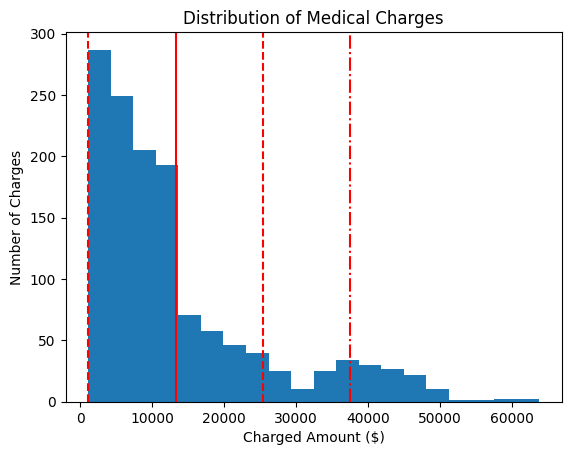

In [4]:
# Calculating Statistics
sample_mean = np.mean(medical.charges)
sample_std = np.std(medical.charges, ddof=1)
sample_median = np.median(medical.charges)

print('Sample Mean: ', sample_mean)
print('Sample Standard Deviation: ', sample_std)
print('Sample Median: ', sample_median)

#  Plotting Histogram of Charges
_ = plt.hist(medical.charges, bins=20)
_ = plt.title('Distribution of Medical Charges')
_ = plt.xlabel('Charged Amount ($)')
_ = plt.ylabel('Number of Charges')
_ = plt.axvline(sample_mean, color='r') # Mean of Sampling Distribution
_ = plt.axvline(sample_mean + sample_std, color='r', linestyle='--') # First Standard Deviation (+)
_ = plt.axvline(sample_mean + 2*sample_std, color='r', linestyle='-.') # Second Standard Deviation (+)

neg_sig1 = sample_mean - sample_std
neg_sig2 = sample_mean - 2*sample_std
if neg_sig1 >= 0:
    _ = plt.axvline(neg_sig1, color='r', linestyle='--') # First Standard Deviation (-)
if neg_sig2 >= 0:
    _ = plt.axvline(neg_sig2, color='r', linestyle='-.') # Second Standard Deviation (-)

From looking at the histogram, it is questionable if these statistics are going to be useful in describing this non-normal distribution. Most of the charges are actually below the mean, so perhaps using the median would be more appropriate for this distribution. The standard deviation is also very large in comparison to the mean, which means its usefulness in future calculations will be highly inaccurate. 

__Q2:__ The administrator is concerned that the actual average charge has fallen below 12,000, threatening the hospital's operational model. On the assumption that these data represent a random sample of charges, how would you justify that these data allow you to answer that question? And what would be the most appropriate frequentist test, of the ones discussed so far, to apply?

__A:__
For this data, it is assumed we are drawing from a random sample of hospital charges. By the Central Limit Theorem (CLT) for large sample sizes, the mean of our sampling distribution will approximate the population mean. This holds true even for non-normal distributions such as this. To test and see if the population mean has fallen below the specified threshold of $\$$12,000 will use a one-sample t-test.

__Q3:__ Given the nature of the administrator's concern, what is the appropriate confidence interval in this case? A ***one-sided*** or ***two-sided*** interval? (Refresh your understanding of this concept on p. 399 of the *AoS*). Calculate the critical value and the relevant 95% confidence interval for the mean, and comment on whether the administrator should be concerned.

__A:__
For this hypothesis test, we can use a one-sided 95% confidence interval. We are only concerned with the section of the distribution which checks if the population mean is below the specified threhold. 

In [5]:
sample_size = len(medical.charges)
threshold = 12000

# Degrees of Freedom
df = sample_size - 1

# Calculating Critical t-value
alpha = 0.05
t_crit = t.ppf(1 - alpha, df).round(2)

# Calculating Confidence Interval (95%)
se = sample_std/np.sqrt(sample_size)
me = t_crit * se
ci = (sample_mean - me, sample_mean + me)

In [6]:
print('Critical t-value: ', t_crit)
print('Standard Error: ', se)
print('Margin of Error: ', me)
print('95% Confidence Interval: ', ci)

if ci[0] < 12000:
    print(f"Administrator should be concerned: The confidence interval suggests the true mean may be below ${threshold:,d}.")
else:
    print(f"Administrator should NOT be concerned: The confidence interval suggests the true mean is above ${threshold:,d}.")

Critical t-value:  1.65
Standard Error:  331.0674543156824
Margin of Error:  546.261299620876
95% Confidence Interval:  (12724.160965520381, 13816.683564762132)
Administrator should NOT be concerned: The confidence interval suggests the true mean is above $12,000.


The administrator then wants to know whether people with insurance really are charged a different amount to those without.

__Q4:__ State the null and alternative hypothesis here. Use the _t_-test for the difference between means, where the pooled standard deviation of the two groups is given by:
\begin{equation}
s_p = \sqrt{\frac{(n_0 - 1)s^2_0 + (n_1 - 1)s^2_1}{n_0 + n_1 - 2}}
\end{equation}

and the *t*-test statistic is then given by:

\begin{equation}
t = \frac{\bar{x}_0 - \bar{x}_1}{s_p \sqrt{1/n_0 + 1/n_1}}.
\end{equation}

(If you need some reminding of the general definition of ***t-statistic***, check out the definition on p. 404 of *AoS*). 

What assumption about the variances of the two groups are we making here?

__A:__
The null hypothesis ($H_0$) of "The mean charges for insured and uninsured patients are the same.". 

\begin{equation}
H_{0}: \mu_0 = \mu_1
\end{equation}

Our alternative hypothesis ($H_1$) is "The mean charges are different."

\begin{equation}
H_{1}: \mu_0 \neq \mu_1
\end{equation}

In [7]:
# Split data between insured and uninsured patient charges
insured = medical[medical.insuranceclaim == 1].charges
uninsured = medical[medical.insuranceclaim == 0].charges

# Sample Statistics
x0, s0, n0 = np.mean(insured), np.std(insured, ddof=1), len(insured)
x1, s1, n1 = np.mean(uninsured), np.std(uninsured, ddof=1), len(uninsured)

# Calculated Pooled Standard Deviation
sp = np.sqrt(((n0-1)*s0**2 + (n1-1)*s1**2) / (n0 + n1 -2))

# Calculate t-statistic
t_stat = (x0 - x1) / (sp*np.sqrt(1/n0 + 1/n1))

# Calculate Critical t-value
t_crit = t.ppf(1 - alpha/2, df = n0 + n1 - 2).round(2)

print(f"t-statistic: {t_stat}")
print(f"Critical t-value: {t_crit}")

# Decision
if abs(t_stat) > t_crit:
    print("Reject H0: Evidence suggests a significant difference in charges.")
else:
    print("Fail to reject H0: No strong evidence of a difference in charges.")


t-statistic: 11.89329903087671
Critical t-value: 1.96
Reject H0: Evidence suggests a significant difference in charges.


__Q5:__ Perform this hypothesis test both manually, using the above formulae, and then using the appropriate function from [scipy.stats](https://docs.scipy.org/doc/scipy/reference/stats.html#statistical-tests) (hint, you're looking for a function to perform a _t_-test on two independent samples). For the manual approach, calculate the value of the test statistic and then its probability (the p-value). Verify you get the same results from both.

__A:__ 

In [8]:
t_stat_scipy, p_value = stats.ttest_ind(insured, uninsured, equal_var=True)

In [9]:
print(f"T-statistic (SciPy): {t_stat_scipy}")
print(f"P-value (SciPy): {p_value}")

T-statistic (SciPy): 11.893299030876712
P-value (SciPy): 4.461230231620717e-31


In [10]:
if p_value < 0.05:
    print("Reject H0: Insured and uninsured patients are charged differently.")
else:
    print("Fail to reject H0: No strong evidence of a difference in charges.")

Reject H0: Insured and uninsured patients are charged differently.


Congratulations! Hopefully you got the exact same numerical results. This shows that you correctly calculated the numbers by hand. Secondly, you used the correct function and saw that it's much easier to use. All you need to do is pass your data to it.

__Q6:__ Conceptual question: look through the documentation for statistical test functions in scipy.stats. You'll see the above _t_-test for a sample, but can you see an equivalent one for performing a *z*-test from a sample? Comment on your answer.

__A:__
In SciPy there does NOT seem to be an equivalent function for performing a ztest from a sample.

## Learning outcomes

Having completed this project notebook, you now have good hands-on experience:
* using the central limit theorem to help you apply frequentist techniques to answer questions that pertain to very non-normally distributed data from the real world
* performing inference using such data to answer business questions
* forming a hypothesis and framing the null and alternative hypotheses
* testing this using a _t_-test